In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from plotting import plot_uncertainty_all_envs
from uncertainty_quantification import uncertainty_quantification

DATA_DIR = "results_corr/posteriors/"
FIGURES_DIR = "figures/"
timesteps = np.arange(100, 5001, 100)
experiments= np.arange(0, 100)
environments = ["EgeExp1", "EgeExp2", "EgeExp3", "EgeExp4", "EgeExp5", "EgeExp6", "EgeExp7", "EgeExp8"]

In [ ]:
# Increase the font size of the plots
plt.rcParams.update({'font.size': 14})
# Change the font to a fancy serif font for use in a latex document
plt.rcParams.update({'font.family': 'serif'})

In [2]:
env_post_dfs = {env: [[pd.read_parquet(DATA_DIR + f"TTPFTS_post_{env}_e{e}_t{t}.parquet", columns=["arm", "means", "stds"]) for t in timesteps] for e in experiments] for env in environments}

In [3]:
env_uncertainties = {env: np.array([[uncertainty_quantification(env_post_dfs[env][i][j]) for j in range(len(timesteps))] for i in range(len(experiments))]) for env in environments}

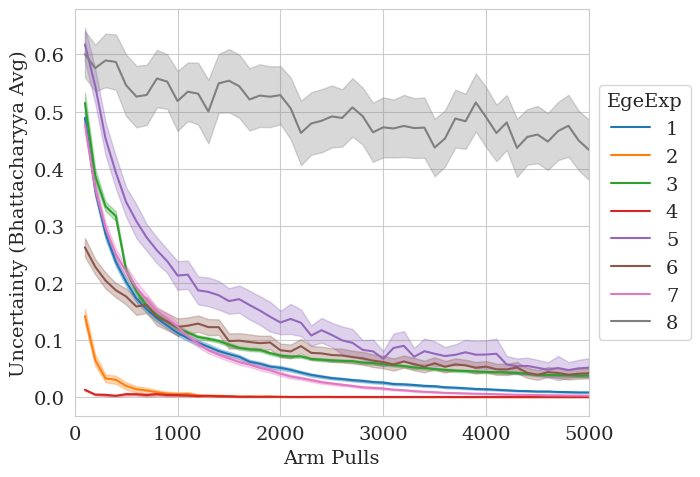

In [15]:
plot_uncertainty_all_envs(
    env_uncertainties,
    timesteps,
    save_png=False,
    save_file=FIGURES_DIR + "uncertainty_quantification_all_envs_singleplot.png",
)

In [6]:
pfi_dfs = [pd.read_csv(f"results_corr/pfi_metrics/TTPFTS_EgeExp{i}_100_5000.csv", names=["algorithm", "experiment", "arm_pull", "bernoulli", "jaccard", "mis_id"], header=None) for i in range(1, 9)]

In [7]:
# For each experiment, keep only the rows where the arm_pull is in timesteps
pfi_dfs = [pfi_df[pfi_df['arm_pull'].isin(timesteps)] for pfi_df in pfi_dfs]

In [8]:
# Add the uncertainty values to the pfi_df
for i, pfi_df in enumerate(pfi_dfs):
    uncertainties = env_uncertainties[f"EgeExp{i+1}"]
    pfi_df['uncertainty'] = uncertainties.flatten()

In [9]:
# Examine the correlation between uncertainty and each of the PFI metrics
correlations = pfi_dfs[0][["bernoulli", "jaccard", "mis_id", "uncertainty"]].corr()
print(correlations["uncertainty"])

bernoulli     -0.347464
jaccard       -0.858168
mis_id         0.878121
uncertainty    1.000000
Name: uncertainty, dtype: float64


In [10]:
# # Plot a heatmap of the correlations
# sns.heatmap(correlations, annot=True, cmap="coolwarm")

In [11]:
# Create a box plot of the per-experiment correlations between uncertainty and each PFI metric
per_env_experiment_correlations = {}

for i, pfi_df in enumerate(pfi_dfs):
    per_experiment_correlations = []
    for e in experiments:
        exp_df = pfi_df[pfi_df['experiment'] == e]
        corr_bernoulli = exp_df["bernoulli"].corr(exp_df["uncertainty"])
        corr_jaccard = exp_df["jaccard"].corr(exp_df["uncertainty"])
        corr_mis_id = exp_df["mis_id"].corr(exp_df["uncertainty"])
        per_experiment_correlations.append({"experiment": e, "bernoulli": corr_bernoulli, "jaccard": corr_jaccard, "mis_id": corr_mis_id})
        per_experiment_corr_df = pd.DataFrame(per_experiment_correlations)
    per_env_experiment_correlations[f"EgeExp{i+1}"] = per_experiment_corr_df

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [12]:
# Combine all per-environment experiment correlations into a single DataFrame for plotting
all_envs_corr_df = pd.concat(
    [per_env_experiment_correlations[env].assign(environment=env) for env in environments],
    ignore_index=True,
)

In [13]:
print(all_envs_corr_df.head())

   experiment  bernoulli   jaccard    mis_id environment
0           0  -0.199900 -0.950461  0.942916     EgeExp1
1           1  -0.111800 -0.934250  0.947498     EgeExp1
2           2  -0.414338 -0.902162  0.908569     EgeExp1
3           3  -0.388508 -0.930101  0.925046     EgeExp1
4           4  -0.310024 -0.916015  0.929439     EgeExp1


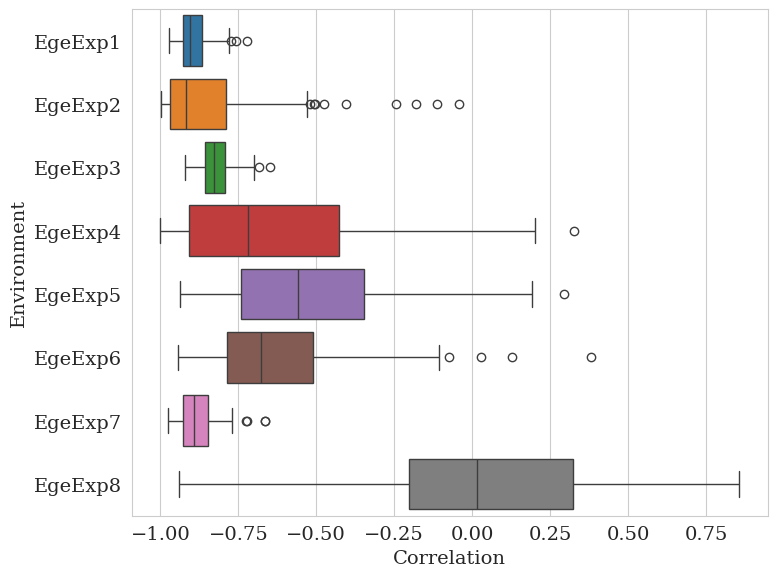

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'all_envs_corr_df' is your existing dataframe.
# Ensure the columns are correct: 'jaccard' and 'environment'

# Set the style for the plot
sns.set_style("whitegrid", {'font.family': 'serif'})

# Create the figure
plt.figure(figsize=(8, 6))

# Create horizontal box plots
# x='jaccard' maps the correlation values to the horizontal axis
# y='environment' maps the environments to the vertical axis
sns.boxplot(
    data=all_envs_corr_df,
    x='jaccard',
    y='environment',
    hue='environment',
    orient='h',
    fill=True,
)

# Customize the labels and title
# plt.title('Correlation with Jaccard Metric by Environment', fontsize=15)
plt.xlabel('Correlation', fontsize=14)
plt.ylabel('Environment', fontsize=14)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Save the plot
plt.savefig(FIGURES_DIR + 'jaccard_correlation_boxplot.png', format='png', dpi=500)

# Show the plot (optional if running in a notebook)
plt.show()